# Water Rights Restored to the Gila River

The impacts of irrigation on vegetation health in the Gila River Valley


## Set up
To get started on this notebook, you’ll need to restore any variables from previous notebooks to your workspace. To save time and memory, make sure to specify which variables you want to load.

In [6]:
%store -r

Unable to restore variable 'dndvi', ignoring (use %store -d to forget!)
The error was: <class 'KeyError'>


You will also need to import any libraries you are using in this
notebook, since they won’t carry over from the previous notebook:

In [19]:
### import libraries
### working with dataframes
import pandas as pd
import numpy as np

### working with geodataframes
import geopandas as gpd

### making interactive plots of tabular and vector data
import hvplot.pandas
import geoviews
import holoviews
import hvplot
import bokeh
import matplotlib.pyplot as plt

# fixing key error with lon_0
import cartopy

### work with json data
import json

### work with pattern matching rules for pathnames 
from glob import glob

### access the data we'll use for the assignment
import earthpy

### interactive plots with rasters 
import hvplot.xarray

### handle geospatial rasters
import rioxarray as rxr

### work with arrays
import xarray as xr

In [10]:
ndvi = xr.open_dataset("ndvi.nc")

In [11]:
ndvi
gila_gdf

,geometry,AIANNHCE,TRSUBCE,TRSUBNS,GEOID,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON
0,"POLYGON ((-111.6827 33.11763, -111.67251 33.11...",1310,200,02418909,1310200,2,District 2,28,D7,G2300,N,80067751,0,+33.0422261,-111.6615277


## Step 4: Plot NDVI

To plot the change in NDVI spatially, complete the following:

1. Calculate the mean NDVI before the water rights case (2001-2007):
    - Take the temporal mean (over the **date**, not spatially)  
    - Specify that you want the mean NDVI value 

2. Repeat this process to calculate the mean NDVI for the years after the water rights case (2013-2022)

3. Calculate the difference in the mean NDVI across the two time periods.
    - Subtract the 2013-2022 time period from the 2001-2007 time period   

4. Plot the result
    - Use a **diverging** color map like `cmap = plt.cm.PiYG`. There are different types of color maps for different types of data. In this case, we want decreases to be a different color from increases, so we should use a diverging color map. Check out available colormaps in the [matplotlib documentation](https://matplotlib.org/stable/tutorials/colors/colormaps.html)

In [14]:
import cartopy.crs as ccrs

# Save the original property only once, so re-running the cell doesn't stack patches
if not hasattr(ccrs.PlateCarree, '_original_proj4_params'):
    ccrs.PlateCarree._original_proj4_params = ccrs.PlateCarree.proj4_params

    def _proj4_params_with_lon_0(self):
        params = ccrs.PlateCarree._original_proj4_params.fget(self)
        params.setdefault('lon_0', params.get('pm', 0))
        return params

    ccrs.PlateCarree.proj4_params = property(_proj4_params_with_lon_0)

In [15]:
### calculate the pre-event NDVI
ndvi_pre = ndvi.sel(date = slice('2001-01-01', '2007-12-31')).mean(dim = 'date')

### calculate the post-event NDVI (2013 to 2022), same idea
ndvi_post = ndvi.sel(date = slice('2013-01-01', '2022-12-31')).mean(dim = 'date')

### calculate the change in NDVI
dndvi = ndvi_pre - ndvi_post

### plot the difference
hvplot.extension('bokeh')
'''(
    dndvi.hvplot(x = '', y = '', cmap = '', geo = True)
    *

    ### add the Gila River Indian Community boundary to your map
    gila_gdf.hvplot(geo = True, fill_color = None, line_color = 'black')
)'''
dndvi.hvplot(x = 'x', y = 'y', cmap = 'PiYG', geo = True)

BokehModel(combine_events=True, render_bundle={'docs_json': {'bc0632e3-8e8a-4807-807e-0938f8ebab7e': {'version…


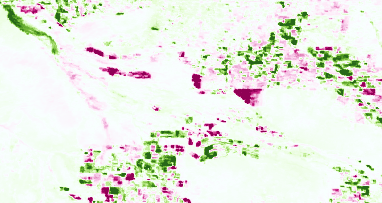

In [28]:
import folium
from matplotlib import colors
import branca.colormap as bcm

d = dndvi.squeeze()
# had to assign the CRS explicitly
dndvi = dndvi.rio.write_crs("EPSG:4326")
d = dndvi["NDVI"].rio.reproject("EPSG:4326").squeeze()

minx, miny, maxx, maxy = dndvi.rio.bounds()

arr = d.values
if d.y.values[0] < d.y.values[-1]:
    arr = np.flipud(arr)
# vals to colors (symmetric around 0 so PiYG is centered)
vmax = np.nanpercentile(np.abs(arr), 98)
norm = colors.Normalize(vmin=-vmax, vmax=vmax)
cmap = plt.get_cmap('PiYG').copy()
cmap.set_bad(alpha=0)                    # NaNs -->   transparent
rgba = cmap(norm(np.ma.masked_invalid(arr)))

# maaaaaap
m = folium.Map(location=[(miny + maxy) / 2, (minx + maxx) / 2], zoom_start=9, tiles=None)

#m = folium.Map(location=[(miny + maxy) / 2, (minx + maxx) / 2], zoom_start=9, tiles='OpenStreetMap')
#m = folium.Map(location=[(miny + maxy) / 2, (minx + maxx) / 2], zoom_start=9, tiles='CartoDB positron')
folium.TileLayer(tiles='https://tile.opentopomap.org/{z}/{x}/{y}.png', attr='OpenStreetMap contributors, SRTM | Style: OpenTopoMap (CC-BY-SA)', name='OpenTopoMap').add_to(m)

folium.raster_layers.ImageOverlay(image=rgba, bounds=[[miny, minx], [maxy, maxx]], opacity=0.7,  name='NDVI change (pre - post)').add_to(m)

# Gila River Indian Community boundary
folium.GeoJson(gila_gdf.to_crs('EPSG:4326'),
    name='Gila River Indian Community',
    style_function=lambda x: {'fillOpacity': 0, 'color': 'black', 'weight': 2}).add_to(m)

# toggletoggletoggletoggle
legend = bcm.LinearColormap([plt.get_cmap('PiYG')(i) for i in np.linspace(0, 1, 7)],vmin=-vmax, vmax=vmax, caption='dNDVI (pre - post)')
legend.add_to(m)
folium.LayerControl().add_to(m)

# save mi work
m.save('dndvi_map3.html')
m

## Wrap up Step 4

Don’t forget to store your variables so you can use them in other notebooks! Replace `var1` and `var2` with the variable you want to save, separated by spaces.

In [30]:
type(dndvi)
dndvi.to_netcdf("dndvi.nc")

In [31]:
%store dndvi ndvi_post ndvi_pre

Stored 'dndvi' (Dataset)
Stored 'ndvi_post' (Dataset)
Stored 'ndvi_pre' (Dataset)


Finally, be sure to `Restart` and `Run all` to make sure your notebook
works all the way through!